# Spectrum Representation & Encoder — Final Notebook
### UTS Deep Learning 2026 | Task 3: Multimodal Clustering | Anggota 2

Notebook ini mendokumentasikan seluruh alur kerja **Spectrum Representation dan Spectrum Encoder** dari awal sampai ekspor embedding. Bagian ini merupakan kontribusi Anggota 2 dan akan menjadi salah satu input pada tahap *multimodal feature fusion* bersama image embedding dari Anggota 1.

**Tujuan:** mempelajari representasi laten dari 128 fitur spektrum komposisi menggunakan pendekatan unsupervised Deep Learning, yaitu **1D Convolutional Autoencoder (1D-CNN Autoencoder)**.

**Alur kerja:**
1. Memuat dataset dan memvalidasi kesesuaian metadata.
2. Melakukan EDA dan visualisasi spektrum.
3. Menyiapkan data dan preprocessing.
4. Membagi data train-validation tanpa label target, dengan stratifikasi berdasarkan mikroskop untuk menjaga proporsi M1/M2.
5. Melatih 1D-CNN Autoencoder untuk merekonstruksi spektrum.
6. Mengevaluasi reconstruction loss dan memeriksa contoh rekonstruksi.
7. Mengekstrak embedding seluruh sampel.
8. Menyimpan embedding, ID sampel, model, scaler, konfigurasi, dan ringkasan eksperimen.

**Batasan:** notebook ini menyelesaikan cabang spectrum encoder, bukan keseluruhan Task 3. Feature fusion, pemilihan jumlah cluster, algoritma clustering, evaluasi cluster, visualisasi gabungan, dan `cluster.csv` dikerjakan bersama setelah image embedding tersedia.

**Catatan interpretasi:** 128 kolom diperlakukan sebagai urutan fitur spektrum. Kamus data tidak memberikan satuan atau panjang gelombang fisik, sehingga sumbu horizontal disebut *feature index*.

## 0. Environment, reproducibility, dan konfigurasi

In [1]:
import os, json, random, zipfile, copy, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from IPython.display import display
warnings.filterwarnings("ignore")

SEED = 42
BATCH_SIZE = 256
EPOCHS = 60
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-5
LATENT_DIM = 32
PATIENCE = 10
VAL_SIZE = 0.15
NUM_WORKERS = 0

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Device :", DEVICE)
if DEVICE.type == "cuda":
    print("GPU    :", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cpu
Device : cpu


**Penjelasan:** cell ini mengatur pustaka, random seed, perangkat komputasi, dan hyperparameter. GPU direkomendasikan untuk mempercepat training, tetapi notebook tetap dapat berjalan di CPU dengan waktu lebih lama. `LATENT_DIM=32` berarti setiap sampel akan direpresentasikan oleh 32 angka embedding.

## 1. Upload dataset secara manual

Upload dua file yang disediakan untuk Task 3:
- `clustering.npz`
- `clustering_meta.csv`

Array `spektrum` digunakan pada notebook ini. Array `gambar` tetap berada di file sumber dan akan digunakan oleh anggota kelompok yang mengerjakan image encoder.

In [2]:
from google.colab import files

uploaded = files.upload()
uploaded_names = list(uploaded.keys())

def find_uploaded_file(keyword):
    matches = [f for f in uploaded_names if keyword.lower() in f.lower()]
    if not matches:
        raise FileNotFoundError(f"File dengan kata '{keyword}' tidak ditemukan.")
    return "/content/" + matches[0]

NPZ_PATH = find_uploaded_file("clustering.npz")
META_PATH = find_uploaded_file("clustering_meta.csv")

print("Dataset NPZ :", NPZ_PATH)
print("Metadata    :", META_PATH)

Saving clustering.npz to clustering.npz
Saving clustering_meta.csv to clustering_meta.csv
Dataset NPZ : /content/clustering.npz
Metadata    : /content/clustering_meta.csv


## 2. Load data dan validasi struktur

In [3]:
npz = np.load(NPZ_PATH)
print("NPZ keys:", npz.files)

assert "spektrum" in npz.files, "Array 'spektrum' tidak ditemukan."
spectrum_raw = npz["spektrum"]
spectrum = spectrum_raw.astype(np.float32)
metadata = pd.read_csv(META_PATH)

required_cols = ["indeks", "id_sampel", "mikroskop"]
missing_cols = [c for c in required_cols if c not in metadata.columns]
assert not missing_cols, f"Kolom metadata tidak lengkap: {missing_cols}"

print("Spectrum shape:", spectrum.shape)
print("Original dtype:", spectrum_raw.dtype)
print("Working dtype :", spectrum.dtype)
print("Metadata shape:", metadata.shape)
display(metadata.head())

NPZ keys: ['gambar', 'spektrum']
Spectrum shape: (36000, 128)
Original dtype: float16
Working dtype : float32
Metadata shape: (36000, 3)


,indeks,id_sampel,mikroskop
0,0,S966119,M1
1,1,S315633,M2
2,2,S805122,M1
3,3,S467543,M1
4,4,S475842,M1


**Interpretasi:** dataset sesuai kamus data apabila `spektrum` memiliki bentuk `(36000, 128)` dan metadata memiliki 36.000 baris dengan kolom `indeks`, `id_sampel`, dan `mikroskop`. Data dikonversi ke `float32` untuk operasi numerik dan training PyTorch.

In [4]:
assert spectrum.ndim == 2, "Spektrum harus berupa array 2 dimensi."
assert spectrum.shape[0] == len(metadata), "Jumlah sampel dan metadata tidak sama."
assert spectrum.shape[1] == 128, f"Diharapkan 128 fitur, ditemukan {spectrum.shape[1]}."
assert metadata["id_sampel"].notna().all(), "Ada ID sampel kosong."
assert metadata["id_sampel"].is_unique, "ID sampel tidak unik."
assert metadata["indeks"].is_unique, "Kolom indeks tidak unik."
assert np.array_equal(metadata["indeks"].to_numpy(), np.arange(len(metadata))), (
    "Kolom indeks tidak berurutan sesuai posisi array. Perlu alignment berdasarkan indeks."
)

print("Validasi struktur dan alignment berhasil.")
print("Jumlah sampel:", len(spectrum))
print("Jumlah fitur :", spectrum.shape[1])
print("Jumlah ID unik:", metadata["id_sampel"].nunique())
display(metadata["mikroskop"].value_counts().rename("jumlah_sampel").to_frame())

Validasi struktur dan alignment berhasil.
Jumlah sampel: 36000
Jumlah fitur : 128
Jumlah ID unik: 36000


,jumlah_sampel
mikroskop,
M1,21636
M2,14364


**Mengapa alignment penting?** embedding yang dihasilkan harus tetap terhubung dengan `id_sampel` yang benar. Kolom `indeks` menunjukkan bahwa baris metadata ke-i sesuai dengan baris ke-i pada array spektrum. Urutan ini dipertahankan hingga ekspor.

## 3. Exploratory Data Analysis (EDA)

### 3.1 Ringkasan kualitas data

In [5]:
n_samples, n_features = spectrum.shape
nan_count = int(np.isnan(spectrum).sum())
inf_count = int(np.isinf(spectrum).sum())
feature_std = np.nanstd(spectrum, axis=0)
constant_idx = np.where(feature_std < 1e-8)[0]

eda_summary = pd.DataFrame({
    "Metrik": [
        "Jumlah sampel", "Jumlah fitur", "Missing values (NaN)",
        "Infinite values", "Jumlah fitur konstan",
        "Nilai minimum", "Nilai maksimum", "Rata-rata", "Standar deviasi"
    ],
    "Nilai": [
        n_samples, n_features, nan_count, inf_count, len(constant_idx),
        float(np.nanmin(spectrum)), float(np.nanmax(spectrum)),
        float(np.nanmean(spectrum)), float(np.nanstd(spectrum))
    ]
})
display(eda_summary)

,Metrik,Nilai
0,Jumlah sampel,36000.000000
1,Jumlah fitur,128.000000
2,Missing values (NaN),0.000000
3,Infinite values,0.000000
4,Jumlah fitur konstan,0.000000
5,Nilai minimum,-1.663086
6,Nilai maksimum,6.152344
7,Rata-rata,0.448439
8,Standar deviasi,0.406897


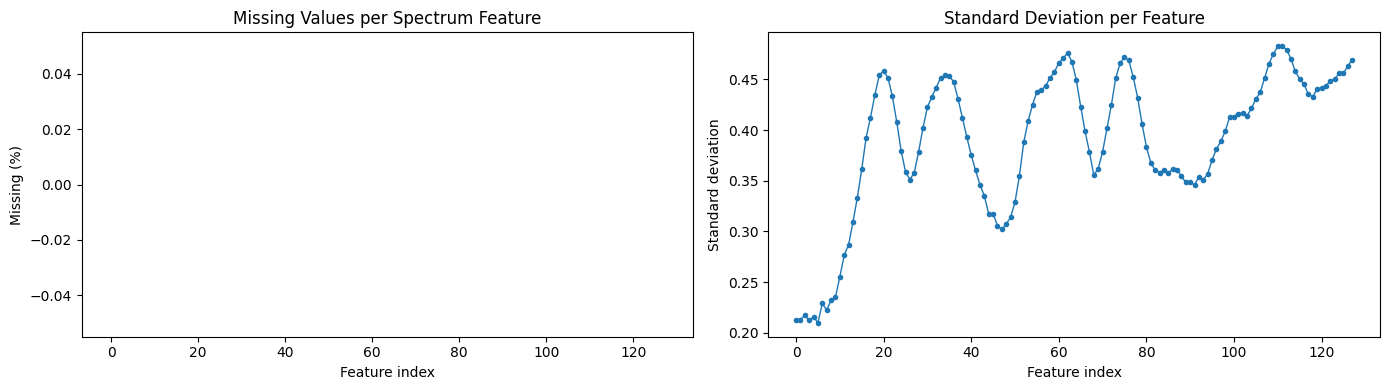

In [6]:
missing_pct = np.isnan(spectrum).mean(axis=0) * 100
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].bar(np.arange(n_features), missing_pct)
ax[0].set(title="Missing Values per Spectrum Feature", xlabel="Feature index", ylabel="Missing (%)")
ax[1].plot(np.arange(n_features), feature_std, marker=".", linewidth=1)
ax[1].set(title="Standard Deviation per Feature", xlabel="Feature index", ylabel="Standard deviation")
plt.tight_layout()
plt.show()

**Caption output:** grafik kiri menunjukkan persentase nilai hilang pada setiap fitur. Grafik kanan menunjukkan variasi tiap fitur. Fitur dengan standar deviasi nol tidak memberikan informasi pembeda. Missing values dan infinite values harus ditangani sebelum standardisasi.

### 3.2 Statistik deskriptif fitur

,count,mean,std,min,25%,50%,75%,max
f000,36000.0,0.3054,0.2126,-0.1115,0.1489,0.3013,0.4521,4.3594
f001,36000.0,0.3048,0.2129,-0.1170,0.1494,0.3013,0.4517,4.4180
f002,36000.0,0.3063,0.2172,-0.1333,0.1509,0.3025,0.4519,4.5000
f003,36000.0,0.3061,0.2122,-0.1235,0.1510,0.3035,0.4537,4.4961
f004,36000.0,0.3081,0.2159,-0.1243,0.1517,0.3040,0.4551,4.5742
f005,36000.0,0.3101,0.2097,-0.1190,0.1544,0.3073,0.4575,4.2109
f006,36000.0,0.3166,0.2289,-0.1519,0.1577,0.3107,0.4622,4.5352
f007,36000.0,0.3223,0.2224,-0.1295,0.1625,0.3186,0.4690,4.0508
f008,36000.0,0.3330,0.2321,-0.1248,0.1675,0.3254,0.4785,4.5586
f009,36000.0,0.3467,0.2349,-0.1284,0.1764,0.3391,0.4924,4.5430


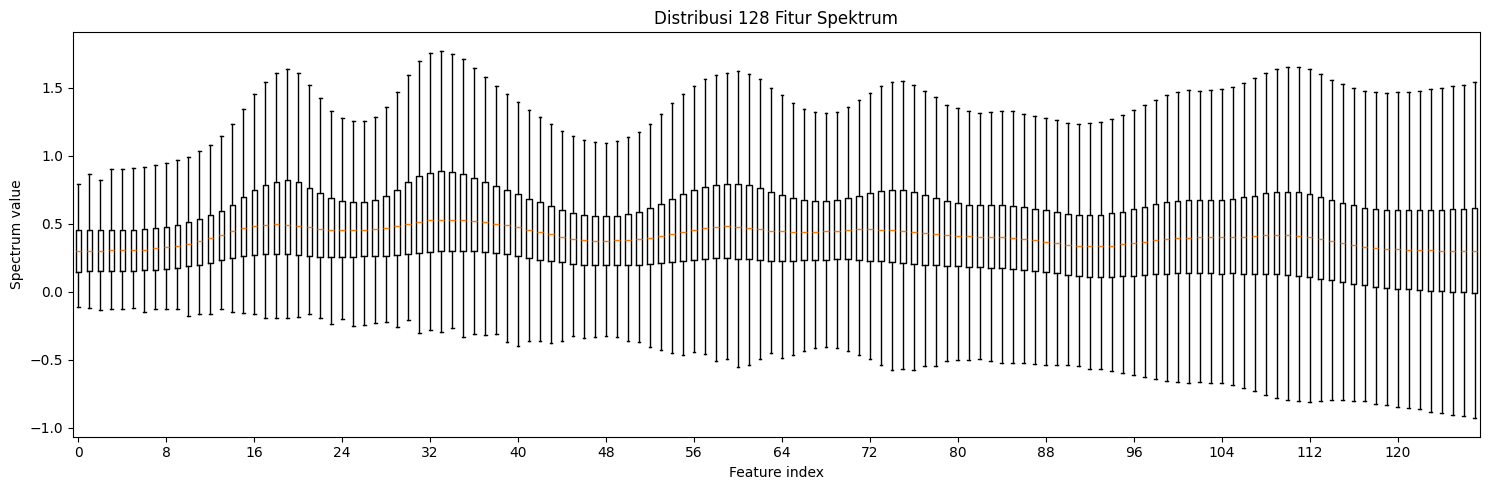

In [7]:
feature_df = pd.DataFrame(spectrum, columns=[f"f{i:03d}" for i in range(n_features)])
feature_stats = feature_df.describe().T
display(feature_stats.round(4).head(20))

plt.figure(figsize=(15, 5))
plt.boxplot(spectrum, showfliers=False)
plt.title("Distribusi 128 Fitur Spektrum")
plt.xlabel("Feature index")
plt.ylabel("Spectrum value")
plt.xticks(np.arange(1, n_features + 1, 8), np.arange(0, n_features, 8))
plt.tight_layout()
plt.show()

**Caption output:** tabel `describe()` memuat mean, standar deviasi, kuartil, minimum, dan maksimum setiap fitur. Boxplot membantu membandingkan skala dan sebaran fitur. Outlier disembunyikan pada visualisasi boxplot agar pola utama terbaca, bukan dihapus dari data.

### 3.3 Visualisasi contoh spektrum

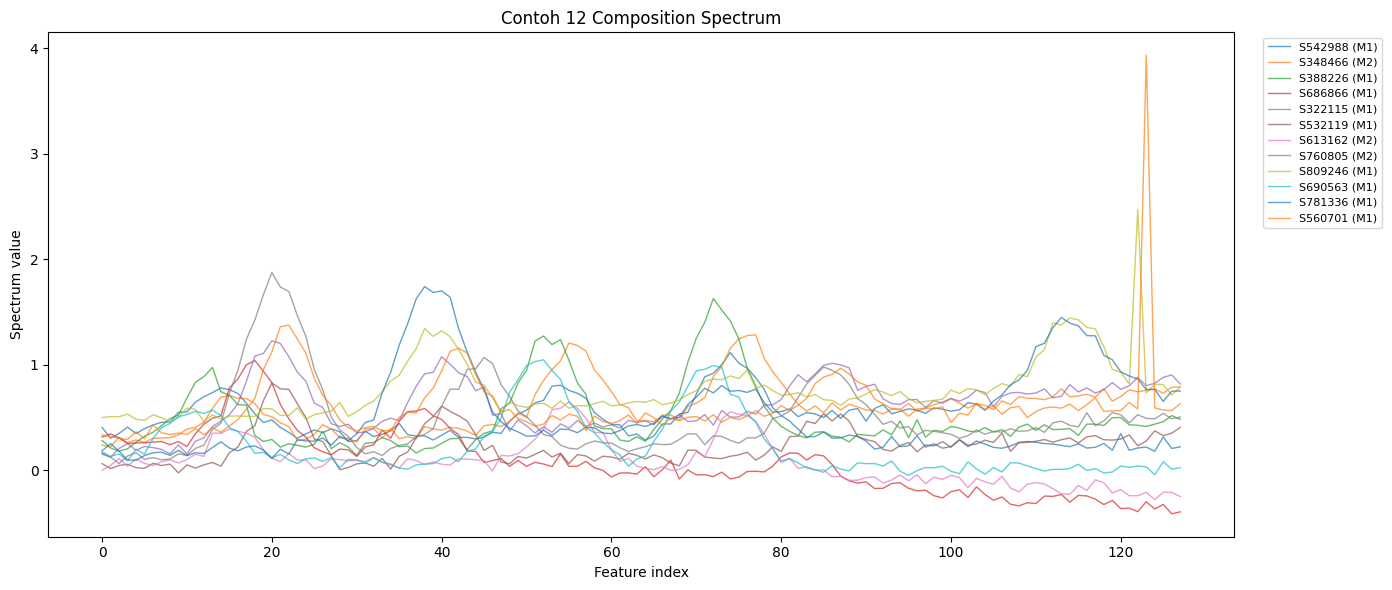

In [8]:
rng = np.random.default_rng(SEED)
example_idx = rng.choice(n_samples, size=min(12, n_samples), replace=False)

plt.figure(figsize=(14, 6))
for i in example_idx:
    plt.plot(np.arange(n_features), spectrum[i], alpha=0.7, linewidth=1,
             label=f"{metadata.iloc[i]['id_sampel']} ({metadata.iloc[i]['mikroskop']})")
plt.title("Contoh 12 Composition Spectrum")
plt.xlabel("Feature index")
plt.ylabel("Spectrum value")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

**Caption output:** setiap garis mewakili satu sampel. Perhatikan pola puncak, perubahan intensitas, dan fluktuasi lokal. Karena data dictionary tidak memberikan unit fisik, indeks fitur tidak boleh disebut sebagai panjang gelombang.

### 3.4 Perbandingan mikroskop M1 dan M2

,jumlah_sampel
mikroskop,
M1,21636
M2,14364


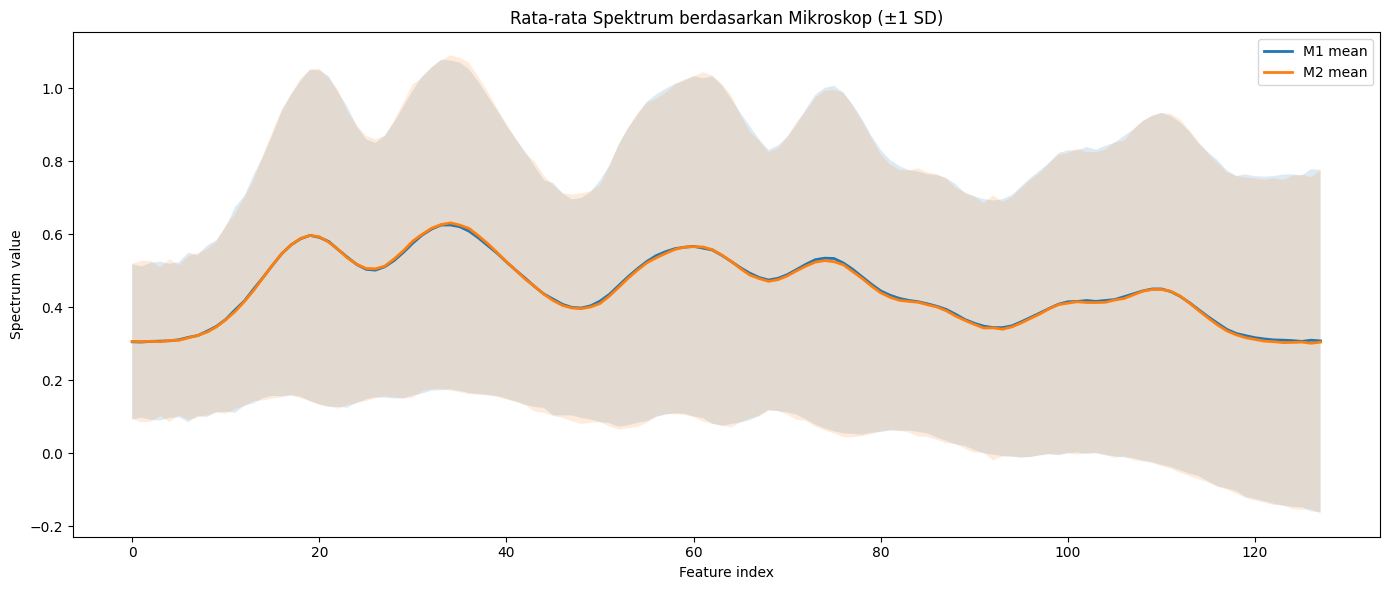

In [9]:
microscope_counts = metadata["mikroskop"].value_counts(dropna=False)
display(microscope_counts.rename("jumlah_sampel").to_frame())

plt.figure(figsize=(14, 6))
for microscope in sorted(metadata["mikroskop"].dropna().unique()):
    mask = metadata["mikroskop"].to_numpy() == microscope
    mean_curve = spectrum[mask].mean(axis=0)
    std_curve = spectrum[mask].std(axis=0)
    x = np.arange(n_features)
    plt.plot(x, mean_curve, linewidth=2, label=f"{microscope} mean")
    plt.fill_between(x, mean_curve-std_curve, mean_curve+std_curve, alpha=0.15)
plt.title("Rata-rata Spektrum berdasarkan Mikroskop (±1 SD)")
plt.xlabel("Feature index")
plt.ylabel("Spectrum value")
plt.legend()
plt.tight_layout()
plt.show()

**Caption output:** perbedaan kurva M1 dan M2 dapat berasal dari variasi alat pengukuran atau komposisi sampel. Informasi mikroskop tidak digunakan sebagai target training. Pada tahap clustering bersama, perlu diperiksa apakah hasil cluster terlalu mengikuti identitas mikroskop (*batch effect*).

### 3.5 Korelasi antarfitur

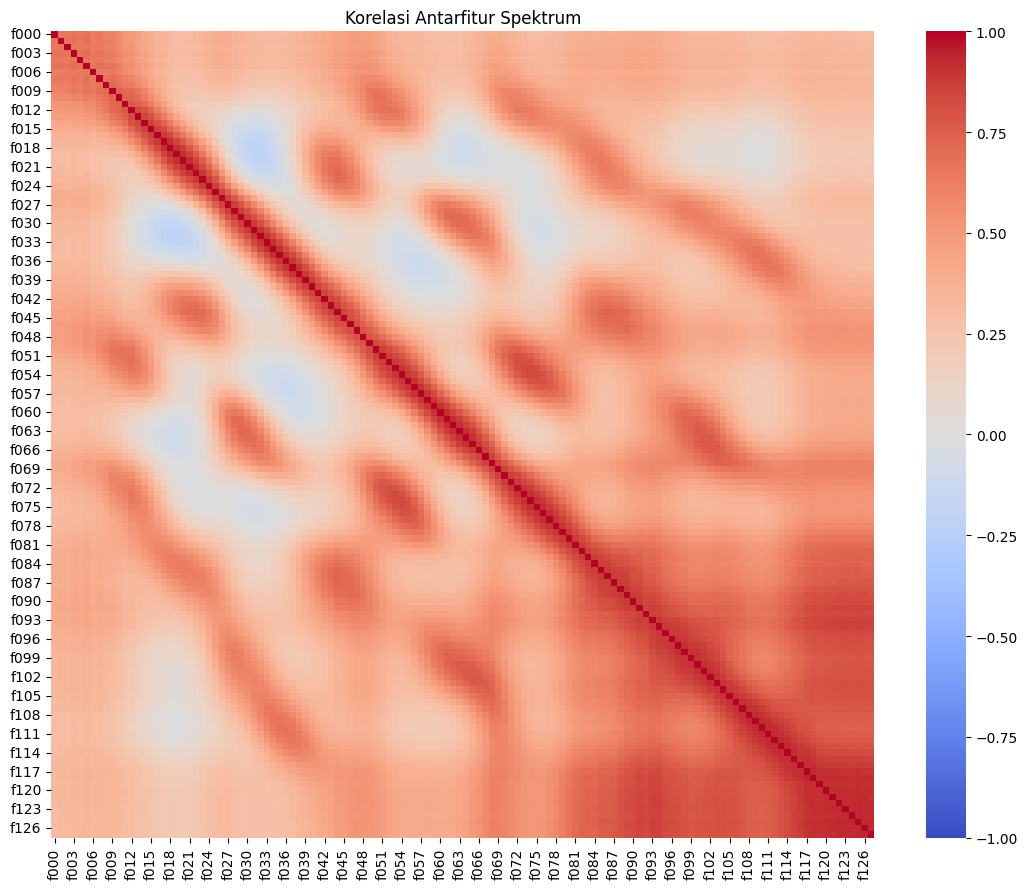

In [10]:
corr = feature_df.corr()
plt.figure(figsize=(11, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Korelasi Antarfitur Spektrum")
plt.tight_layout()
plt.show()

**Caption output:** korelasi positif atau negatif yang kuat menunjukkan fitur bergerak bersama. Korelasi tidak otomatis menjadi alasan menghapus fitur; encoder dapat mempelajari pola hubungan lokal antarf fitur.

### 3.6 Pemeriksaan nilai ekstrem

Sampel dengan minimal satu fitur |z| > 3: 30.82%
Rata-rata proporsi fitur |z| > 3 per sampel: 0.690%


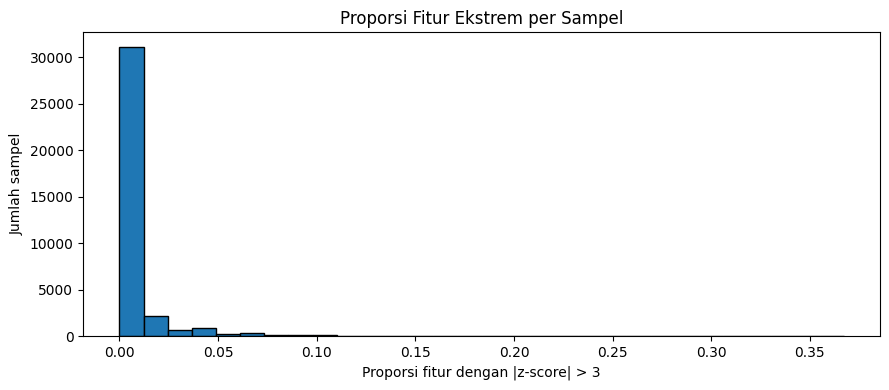

In [11]:
# Z-score per fitur digunakan sebagai indikator eksploratif.
safe_std = spectrum.std(axis=0)
safe_std[safe_std < 1e-8] = 1.0
z = (spectrum - spectrum.mean(axis=0)) / safe_std
outlier_fraction = (np.abs(z) > 3).mean(axis=1)

print("Sampel dengan minimal satu fitur |z| > 3:",
      f"{100*(outlier_fraction > 0).mean():.2f}%")
print("Rata-rata proporsi fitur |z| > 3 per sampel:",
      f"{100*outlier_fraction.mean():.3f}%")

plt.figure(figsize=(9, 4))
plt.hist(outlier_fraction, bins=30, edgecolor="black")
plt.title("Proporsi Fitur Ekstrem per Sampel")
plt.xlabel("Proporsi fitur dengan |z-score| > 3")
plt.ylabel("Jumlah sampel")
plt.tight_layout()
plt.show()

**Interpretasi:** nilai ekstrem tidak otomatis merupakan kesalahan. Pada data spektrum, puncak intensitas dapat menjadi informasi penting. Karena itu, notebook tidak menghapus outlier secara otomatis.

## 4. Preprocessing

### 4.1 Strategi preprocessing

Strategi yang digunakan pada pipeline awal:
- Mengganti nilai `NaN`/`Inf` dengan median masing-masing fitur jika ditemukan.
- Menghapus fitur konstan jika ditemukan.
- Membagi data train dan validation secara stratified berdasarkan kategori mikroskop agar proporsi M1/M2 relatif terjaga.
- Melakukan `StandardScaler` dengan parameter yang di-fit hanya pada data training.
- Menggunakan scaler training yang sama untuk validation dan seluruh data saat ekstraksi embedding.

**Catatan:** standardisasi per fitur dipilih sebagai preprocessing awal agar fitur dengan skala besar tidak mendominasi reconstruction loss. Tidak dilakukan smoothing atau baseline correction otomatis karena bentuk spektrum belum memberikan dasar yang cukup untuk mengubah sinyal.

In [12]:
from sklearn.impute import SimpleImputer

X_raw = spectrum.copy()
X_raw[~np.isfinite(X_raw)] = np.nan

# Buang fitur yang seluruh nilainya kosong atau tidak memiliki variasi.
all_nan_mask = np.isnan(X_raw).all(axis=0)
X_temp = X_raw[:, ~all_nan_mask]
kept_feature_original_indices = np.where(~all_nan_mask)[0]

imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X_temp).astype(np.float32)

var = X_imputed.var(axis=0)
nonconstant_mask = var > 1e-10
X_clean = X_imputed[:, nonconstant_mask].astype(np.float32)
kept_feature_indices = kept_feature_original_indices[nonconstant_mask]

print("Shape awal              :", spectrum.shape)
print("Fitur seluruhnya NaN    :", int(all_nan_mask.sum()))
print("Fitur konstan dibuang   :", int((~nonconstant_mask).sum()))
print("Shape setelah cleaning  :", X_clean.shape)
print("Missing setelah imputasi:", int(np.isnan(X_clean).sum()))

Shape awal              : (36000, 128)
Fitur seluruhnya NaN    : 0
Fitur konstan dibuang   : 0
Shape setelah cleaning  : (36000, 128)
Missing setelah imputasi: 0


**Interpretasi:** jika dataset bersih, bentuk akhir tetap `(36000, 128)`. Jika ada fitur tidak valid atau konstan, jumlah fitur dapat berkurang. Daftar indeks fitur yang dipertahankan disimpan dalam artefak preprocessing.

### 4.2 Train-validation split dan standardisasi

In [13]:
stratify_labels = metadata["mikroskop"].astype(str).to_numpy()
all_indices = np.arange(n_samples)

train_idx, val_idx = train_test_split(
    all_indices,
    test_size=VAL_SIZE,
    random_state=SEED,
    stratify=stratify_labels
)

X_train_raw = X_clean[train_idx]
X_val_raw = X_clean[val_idx]

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw).astype(np.float32)
X_val = scaler.transform(X_val_raw).astype(np.float32)

print("Train samples:", len(train_idx))
print("Validation samples:", len(val_idx))
print("Train shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Train mean (approx):", float(X_train.mean()))
print("Train std (approx):", float(X_train.std()))

Train samples: 30600
Validation samples: 5400
Train shape: (30600, 128)
Validation shape: (5400, 128)
Train mean (approx): -2.4932661490950636e-10
Train std (approx): 1.0


,train,validation
mikroskop,,
M1,0.601013,0.600926
M2,0.398987,0.399074


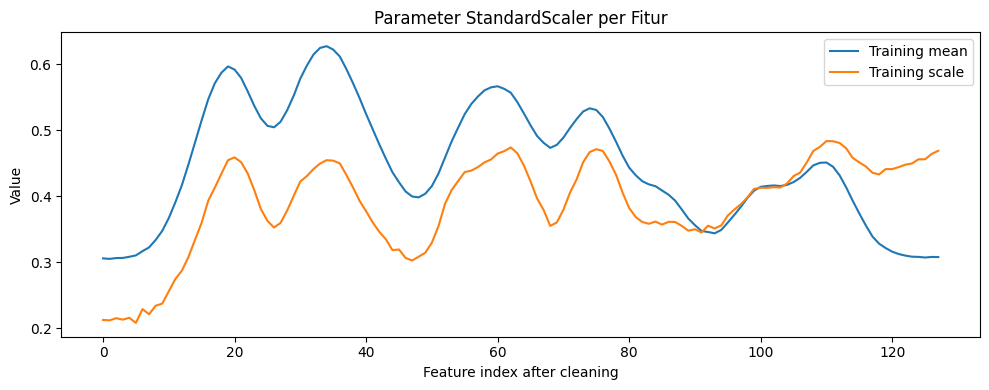

In [14]:
split_check = pd.DataFrame({
    "train": metadata.iloc[train_idx]["mikroskop"].value_counts(normalize=True),
    "validation": metadata.iloc[val_idx]["mikroskop"].value_counts(normalize=True)
}).fillna(0)
display(split_check)

plt.figure(figsize=(10, 4))
plt.plot(scaler.mean_, label="Training mean")
plt.plot(scaler.scale_, label="Training scale")
plt.title("Parameter StandardScaler per Fitur")
plt.xlabel("Feature index after cleaning")
plt.ylabel("Value")
plt.legend()
plt.tight_layout()
plt.show()

**Caption output:** train dan validation dipisahkan agar reconstruction loss dapat dievaluasi pada sampel yang tidak digunakan untuk memperbarui bobot. Stratifikasi mikroskop menjaga komposisi M1/M2 tetap sebanding. Scaler hanya di-fit pada training untuk mencegah informasi validation memengaruhi parameter preprocessing.

## 5. Membangun 1D-CNN Autoencoder

### 5.1 Konsep arsitektur

Autoencoder terdiri dari dua bagian:
- **Encoder:** mengubah spektrum menjadi vektor laten berdimensi 32.
- **Decoder:** merekonstruksi kembali spektrum dari vektor laten.

Model dilatih dengan meminimalkan Mean Squared Error (MSE) antara spektrum input dan hasil rekonstruksi. Setelah training, decoder tidak diperlukan untuk membuat embedding; hanya encoder yang digunakan.

In [15]:
class SpectrumDataset(Dataset):
    def __init__(self, X):
        self.X = torch.tensor(X, dtype=torch.float32)
    def __len__(self):
        return len(self.X)
    def __getitem__(self, idx):
        # Conv1D membutuhkan format (channel, sequence_length).
        return self.X[idx].unsqueeze(0)

class Conv1DSpectrumAutoencoder(nn.Module):
    def __init__(self, input_length, latent_dim=32):
        super().__init__()
        self.input_length = input_length
        self.latent_dim = latent_dim

        self.encoder_conv = nn.Sequential(
            nn.Conv1d(1, 16, kernel_size=5, padding=2),
            nn.BatchNorm1d(16),
            nn.ReLU(),
            nn.MaxPool1d(2),            # L -> L/2

            nn.Conv1d(16, 32, kernel_size=5, padding=2),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(2),            # L/2 -> L/4

            nn.Conv1d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(2)             # L/4 -> L/8
        )

        self.encoded_length = input_length // 8
        self.encoder_fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * self.encoded_length, 128),
            nn.ReLU(),
            nn.Linear(128, latent_dim)
        )

        self.decoder_fc = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 64 * self.encoded_length),
            nn.ReLU()
        )

        self.decoder_conv = nn.Sequential(
            nn.ConvTranspose1d(64, 32, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.ConvTranspose1d(32, 16, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm1d(16),
            nn.ReLU(),
            nn.ConvTranspose1d(16, 1, kernel_size=4, stride=2, padding=1)
        )

    def encode(self, x):
        h = self.encoder_conv(x)
        return self.encoder_fc(h)

    def forward(self, x):
        z = self.encode(x)
        h = self.decoder_fc(z)
        h = h.view(-1, 64, self.encoded_length)
        reconstruction = self.decoder_conv(h)
        # Menjaga panjang output sama dengan panjang input.
        reconstruction = reconstruction[..., :self.input_length]
        return reconstruction, z

model = Conv1DSpectrumAutoencoder(
    input_length=X_train.shape[1],
    latent_dim=LATENT_DIM
).to(DEVICE)

dummy = torch.zeros(2, 1, X_train.shape[1]).to(DEVICE)
with torch.no_grad():
    dummy_recon, dummy_z = model(dummy)

print(model)
print("Input shape         :", tuple(dummy.shape))
print("Reconstruction shape:", tuple(dummy_recon.shape))
print("Latent shape        :", tuple(dummy_z.shape))

Conv1DSpectrumAutoencoder(
  (encoder_conv): Sequential(
    (0): Conv1d(1, 16, kernel_size=(5,), stride=(1,), padding=(2,))
    (1): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv1d(16, 32, kernel_size=(5,), stride=(1,), padding=(2,))
    (5): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv1d(32, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (9): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (encoder_fc): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1024, out_features=128, bias=True

**Interpretasi arsitektur:** convolution mempelajari pola lokal antarfitur spektrum. Pooling mengurangi panjang representasi secara bertahap, sedangkan dense bottleneck mengubah hasil encoder menjadi 32 nilai laten. Decoder berusaha membangun kembali input dari representasi tersebut.

## 6. Training model

In [16]:
train_loader = DataLoader(
    SpectrumDataset(X_train),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda")
)
val_loader = DataLoader(
    SpectrumDataset(X_val),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda")
)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=4
)

def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, total_n = 0.0, 0

    for batch in loader:
        batch = batch.to(DEVICE)
        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):
            reconstruction, _ = model(batch)
            loss = criterion(reconstruction, batch)
            if training:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
                optimizer.step()

        total_loss += loss.item() * batch.size(0)
        total_n += batch.size(0)

    return total_loss / total_n

history = {"train_loss": [], "val_loss": []}
best_val = float("inf")
best_state = None
best_epoch = 0
epochs_without_improvement = 0

for epoch in range(1, EPOCHS + 1):
    train_loss = run_epoch(model, train_loader, optimizer)
    val_loss = run_epoch(model, val_loader, optimizer=None)
    scheduler.step(val_loss)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    if val_loss < best_val:
        best_val = val_loss
        best_epoch = epoch
        best_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    print(
        f"Epoch {epoch:03d}/{EPOCHS} | "
        f"train MSE: {train_loss:.6f} | "
        f"val MSE: {val_loss:.6f}"
    )

    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping pada epoch {epoch}.")
        break

model.load_state_dict(best_state)
print(f"Best epoch: {best_epoch} | Best validation MSE: {best_val:.6f}")

Epoch 001/60 | train MSE: 0.301612 | val MSE: 0.133137
Epoch 002/60 | train MSE: 0.125701 | val MSE: 0.118635
Epoch 003/60 | train MSE: 0.116452 | val MSE: 0.112227
Epoch 004/60 | train MSE: 0.110385 | val MSE: 0.106783
Epoch 005/60 | train MSE: 0.106516 | val MSE: 0.102272
Epoch 006/60 | train MSE: 0.102058 | val MSE: 0.095506
Epoch 007/60 | train MSE: 0.095767 | val MSE: 0.090818
Epoch 008/60 | train MSE: 0.090069 | val MSE: 0.086248
Epoch 009/60 | train MSE: 0.083953 | val MSE: 0.078837
Epoch 010/60 | train MSE: 0.077736 | val MSE: 0.074170
Epoch 011/60 | train MSE: 0.070102 | val MSE: 0.067600
Epoch 012/60 | train MSE: 0.062808 | val MSE: 0.061075
Epoch 013/60 | train MSE: 0.057718 | val MSE: 0.053402
Epoch 014/60 | train MSE: 0.048497 | val MSE: 0.048616
Epoch 015/60 | train MSE: 0.043150 | val MSE: 0.043033
Epoch 016/60 | train MSE: 0.037879 | val MSE: 0.037635
Epoch 017/60 | train MSE: 0.034382 | val MSE: 0.033094
Epoch 018/60 | train MSE: 0.031148 | val MSE: 0.032194
Epoch 019/

**Penjelasan training:** model mempelajari rekonstruksi spektrum pada training set dan dievaluasi pada validation set. Checkpoint dengan validation MSE terendah disimpan. *Early stopping* menghentikan training jika validation loss tidak membaik selama beberapa epoch, untuk mengurangi risiko overfitting.

### 6.1 Learning curve

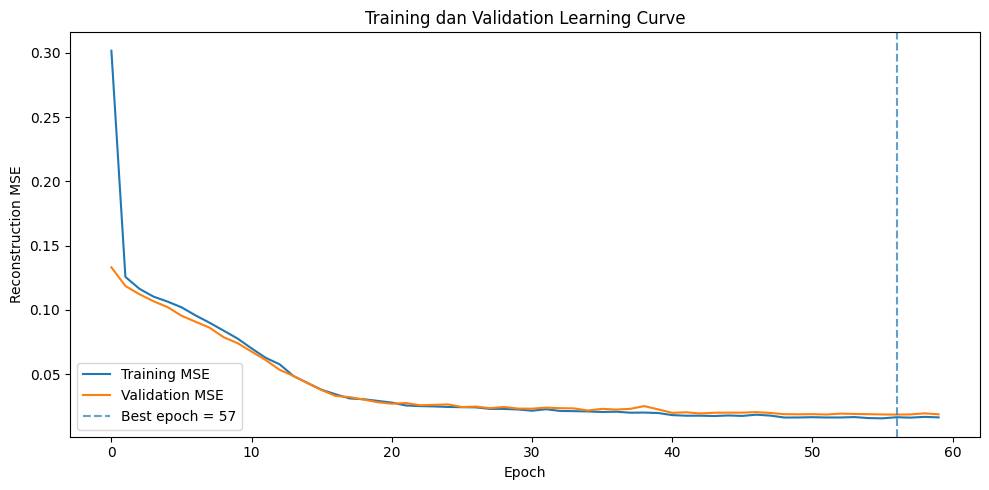

In [17]:
plt.figure(figsize=(10, 5))
plt.plot(history["train_loss"], label="Training MSE")
plt.plot(history["val_loss"], label="Validation MSE")
plt.axvline(best_epoch - 1, linestyle="--", alpha=0.7, label=f"Best epoch = {best_epoch}")
plt.title("Training dan Validation Learning Curve")
plt.xlabel("Epoch")
plt.ylabel("Reconstruction MSE")
plt.legend()
plt.tight_layout()
plt.show()

**Caption output:** kurva yang turun menunjukkan model semakin baik merekonstruksi input. Jika training loss terus turun sementara validation loss naik, model mungkin mengalami overfitting. Epoch terbaik dipilih berdasarkan validation MSE terendah, bukan training loss terendah.

## 7. Evaluasi rekonstruksi

In [18]:
model.eval()
val_recon_list, val_latent_list = [], []
with torch.no_grad():
    for batch in val_loader:
        batch = batch.to(DEVICE)
        reconstruction, latent = model(batch)
        val_recon_list.append(reconstruction.squeeze(1).cpu().numpy())
        val_latent_list.append(latent.cpu().numpy())

X_val_recon_scaled = np.concatenate(val_recon_list, axis=0)
Z_val = np.concatenate(val_latent_list, axis=0)

val_mse = mean_squared_error(X_val, X_val_recon_scaled)
val_mae = mean_absolute_error(X_val, X_val_recon_scaled)
print(f"Validation reconstruction MSE: {val_mse:.6f}")
print(f"Validation reconstruction MAE: {val_mae:.6f}")
print("Validation embedding shape:", Z_val.shape)

Validation reconstruction MSE: 0.018615
Validation reconstruction MAE: 0.092902
Validation embedding shape: (5400, 32)


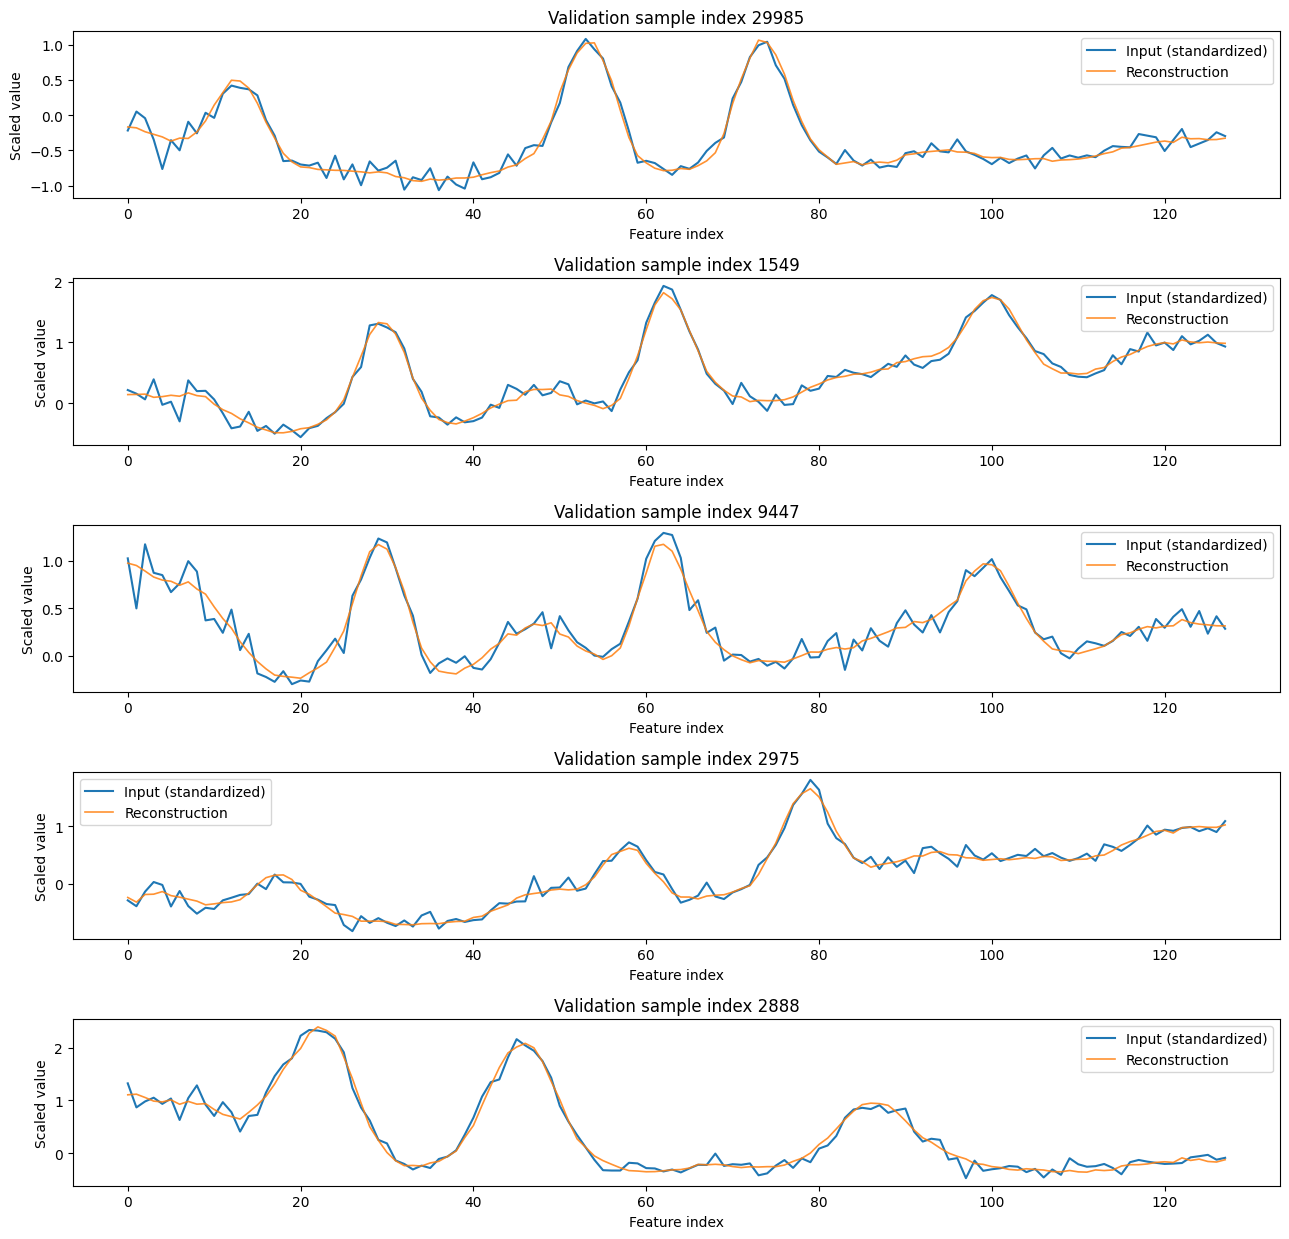

In [19]:
# Pilih beberapa sampel validation dan bandingkan input dengan hasil rekonstruksi.
n_show = min(5, len(X_val))
show_idx = np.random.default_rng(SEED).choice(len(X_val), n_show, replace=False)

fig, axes = plt.subplots(n_show, 1, figsize=(13, 2.5*n_show), squeeze=False)
for row, idx in enumerate(show_idx):
    axes[row, 0].plot(X_val[idx], label="Input (standardized)", linewidth=1.5)
    axes[row, 0].plot(X_val_recon_scaled[idx], label="Reconstruction", linewidth=1.2, alpha=0.85)
    axes[row, 0].set_title(f"Validation sample index {val_idx[idx]}")
    axes[row, 0].set_xlabel("Feature index")
    axes[row, 0].set_ylabel("Scaled value")
    axes[row, 0].legend()
plt.tight_layout()
plt.show()

**Caption output:** garis input dan rekonstruksi yang berdekatan menunjukkan model berhasil mempertahankan pola spektrum. Perbedaan besar pada puncak tertentu dapat menunjukkan pola yang sulit direkonstruksi. Reconstruction loss mengukur kualitas rekonstruksi, bukan kualitas cluster; kualitas embedding tetap harus diuji pada tahap clustering bersama.

## 8. Ekstraksi embedding seluruh 36.000 sampel

Setelah model dipilih berdasarkan validation loss, encoder digunakan untuk mengubah seluruh spektrum yang sudah dipreprocess menjadi embedding berdimensi `LATENT_DIM`. Untuk menghasilkan embedding final, scaler di-fit ulang pada seluruh dataset yang tersedia, kemudian model final dilatih ulang menggunakan seluruh sampel selama `best_epoch` epoch. Dengan demikian, embedding akhir menggunakan seluruh data tanpa menyisakan validation split.

In [20]:
# Fit preprocessing final pada seluruh data.
final_imputer = SimpleImputer(strategy="median")
X_all_temp = spectrum.copy()
X_all_temp[~np.isfinite(X_all_temp)] = np.nan
all_nan_mask_final = np.isnan(X_all_temp).all(axis=0)
X_all_temp = X_all_temp[:, ~all_nan_mask_final]
kept_original_final = np.where(~all_nan_mask_final)[0]

X_all_imputed = final_imputer.fit_transform(X_all_temp).astype(np.float32)
var_final = X_all_imputed.var(axis=0)
nonconstant_final = var_final > 1e-10
X_all_clean = X_all_imputed[:, nonconstant_final].astype(np.float32)
kept_features_final = kept_original_final[nonconstant_final]

final_scaler = StandardScaler()
X_all_scaled = final_scaler.fit_transform(X_all_clean).astype(np.float32)

print("All data shape after preprocessing:", X_all_scaled.shape)

All data shape after preprocessing: (36000, 128)


**Catatan metodologis:** model final di-fit ulang menggunakan seluruh data karena tujuan tahap ini adalah menghasilkan representasi untuk semua sampel yang akan dipakai pada multimodal fusion. Angka validation loss sebelumnya tetap dilaporkan sebagai estimasi performa saat pengembangan model; retraining final tidak memiliki validation set terpisah.

In [21]:
set_seed(SEED)
final_model = Conv1DSpectrumAutoencoder(
    input_length=X_all_scaled.shape[1],
    latent_dim=LATENT_DIM
).to(DEVICE)

all_loader = DataLoader(
    SpectrumDataset(X_all_scaled),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS
)
final_optimizer = torch.optim.Adam(
    final_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

final_train_losses = []
for epoch in range(1, best_epoch + 1):
    loss = run_epoch(final_model, all_loader, final_optimizer)
    final_train_losses.append(loss)
    print(f"Final training epoch {epoch:03d}/{best_epoch} | MSE: {loss:.6f}")

Final training epoch 001/57 | MSE: 0.272983
Final training epoch 002/57 | MSE: 0.121471
Final training epoch 003/57 | MSE: 0.112936
Final training epoch 004/57 | MSE: 0.107428
Final training epoch 005/57 | MSE: 0.100958
Final training epoch 006/57 | MSE: 0.095818
Final training epoch 007/57 | MSE: 0.088918
Final training epoch 008/57 | MSE: 0.083351
Final training epoch 009/57 | MSE: 0.075927
Final training epoch 010/57 | MSE: 0.067557
Final training epoch 011/57 | MSE: 0.060693
Final training epoch 012/57 | MSE: 0.051342
Final training epoch 013/57 | MSE: 0.042833
Final training epoch 014/57 | MSE: 0.036729
Final training epoch 015/57 | MSE: 0.032985
Final training epoch 016/57 | MSE: 0.030993
Final training epoch 017/57 | MSE: 0.029359
Final training epoch 018/57 | MSE: 0.027645
Final training epoch 019/57 | MSE: 0.026332
Final training epoch 020/57 | MSE: 0.025863
Final training epoch 021/57 | MSE: 0.024852
Final training epoch 022/57 | MSE: 0.024416
Final training epoch 023/57 | MS

### 8.1 Final training curve

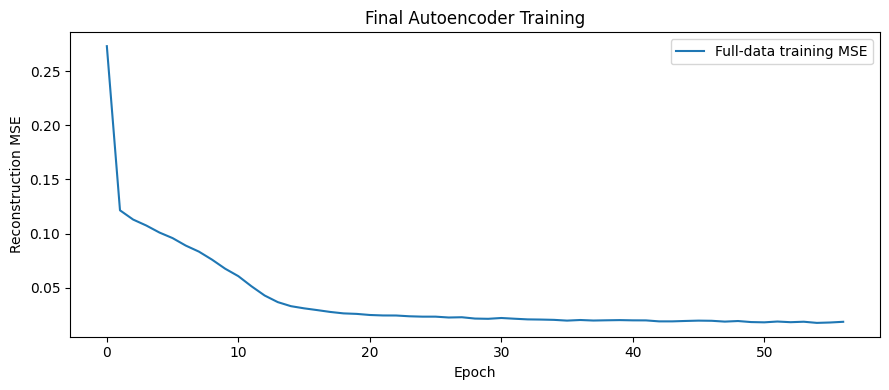

In [22]:
plt.figure(figsize=(9, 4))
plt.plot(final_train_losses, label="Full-data training MSE")
plt.title("Final Autoencoder Training")
plt.xlabel("Epoch")
plt.ylabel("Reconstruction MSE")
plt.legend()
plt.tight_layout()
plt.show()

**Caption output:** kurva ini menunjukkan proses optimisasi model final pada seluruh data. Karena tidak ada validation set pada tahap retraining final, kurva ini tidak digunakan sebagai ukuran generalisasi.

In [23]:
# Encode seluruh sampel dalam urutan asli.
final_model.eval()
all_loader_ordered = DataLoader(
    SpectrumDataset(X_all_scaled),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS
)

embedding_batches = []
with torch.no_grad():
    for batch in all_loader_ordered:
        batch = batch.to(DEVICE)
        z = final_model.encode(batch)
        embedding_batches.append(z.cpu().numpy())

spectrum_embeddings = np.concatenate(embedding_batches, axis=0).astype(np.float32)

print("Spectrum embeddings shape:", spectrum_embeddings.shape)
assert spectrum_embeddings.shape == (len(metadata), LATENT_DIM)

Spectrum embeddings shape: (36000, 32)


**Interpretasi:** setiap sampel kini direpresentasikan oleh 32 nilai laten. Baris ke-i embedding tetap berkorespondensi dengan baris ke-i metadata karena ekstraksi dilakukan tanpa shuffle. Embedding ini akan menjadi input spectrum modality pada tahap fusion.

## 9. Pemeriksaan embedding

In [24]:
embedding_df = pd.DataFrame(
    spectrum_embeddings,
    columns=[f"spectrum_emb_{i:02d}" for i in range(LATENT_DIM)]
)

print("Embedding min/max:", spectrum_embeddings.min(), spectrum_embeddings.max())
print("Embedding mean/std:", spectrum_embeddings.mean(), spectrum_embeddings.std())
print("NaN:", np.isnan(spectrum_embeddings).sum())
print("Inf:", np.isinf(spectrum_embeddings).sum())
display(embedding_df.describe().T.head(10))

Embedding min/max: -10.531448 10.301788
Embedding mean/std: 0.12816244 1.5002977
NaN: 0
Inf: 0


,count,mean,std,min,25%,50%,75%,max
spectrum_emb_00,36000.0,0.181181,1.327081,-5.383513,-0.732229,0.185571,1.097467,6.716482
spectrum_emb_01,36000.0,0.191136,0.907229,-6.030200,-0.434865,0.175825,0.751719,5.673497
spectrum_emb_02,36000.0,0.073731,0.865204,-6.821049,-0.443305,-0.017705,0.562492,6.576047
spectrum_emb_03,36000.0,-0.465891,0.990761,-7.246041,-1.059797,-0.449612,0.169863,5.081140
spectrum_emb_04,36000.0,-1.000599,0.971800,-7.682570,-1.535159,-0.938076,-0.420676,5.608905
spectrum_emb_05,36000.0,1.186727,1.328708,-4.774947,0.290549,1.129582,2.009791,10.301788
spectrum_emb_06,36000.0,-0.036437,1.055019,-6.866381,-0.751413,-0.118349,0.630175,5.476861
spectrum_emb_07,36000.0,1.327077,1.530413,-3.934232,0.276050,1.195147,2.261020,9.772384
spectrum_emb_08,36000.0,0.166253,1.452634,-6.389214,-0.828354,0.046340,1.075559,7.590859
spectrum_emb_09,36000.0,-0.104912,1.018126,-6.278712,-0.717152,-0.081446,0.528826,6.183399


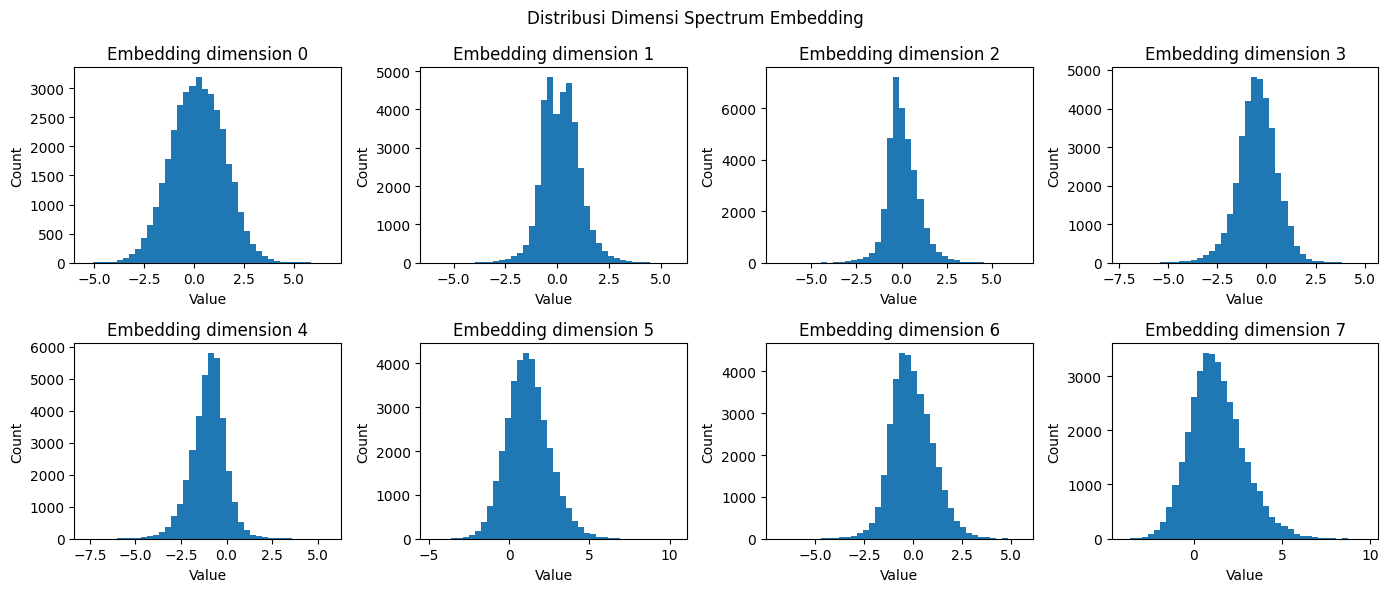

In [25]:
# Visualisasi distribusi beberapa dimensi embedding.
n_dims_plot = min(8, LATENT_DIM)
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for i, ax in enumerate(axes.flat):
    if i < n_dims_plot:
        ax.hist(spectrum_embeddings[:, i], bins=40)
        ax.set_title(f"Embedding dimension {i}")
        ax.set_xlabel("Value")
        ax.set_ylabel("Count")
    else:
        ax.axis("off")
plt.suptitle("Distribusi Dimensi Spectrum Embedding")
plt.tight_layout()
plt.show()

**Caption output:** distribusi ini membantu memeriksa apakah embedding memiliki nilai finite dan variasi. Dimensi yang konstan atau nilai NaN/Inf perlu diselidiki. Distribusi embedding saja belum membuktikan bahwa kelompok material sudah terpisah; hal tersebut diuji setelah fusion dan clustering.

## 10. Simpan artefak spectrum encoder

In [26]:
OUTPUT_DIR = "/content/spectrum_encoder_artifacts"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# CSV memudahkan integrasi dan pengecekan ID; NPY lebih ringkas untuk komputasi.
embedding_output = pd.DataFrame({
    "indeks": metadata["indeks"].to_numpy(),
    "id_sampel": metadata["id_sampel"].astype(str).to_numpy(),
    "mikroskop": metadata["mikroskop"].astype(str).to_numpy()
})
for j in range(LATENT_DIM):
    embedding_output[f"spectrum_emb_{j:02d}"] = spectrum_embeddings[:, j]

embedding_output.to_csv(
    os.path.join(OUTPUT_DIR, "spectrum_embeddings.csv"), index=False
)
np.save(os.path.join(OUTPUT_DIR, "spectrum_embeddings.npy"), spectrum_embeddings)
np.save(os.path.join(OUTPUT_DIR, "spectrum_sample_ids.npy"),
        metadata["id_sampel"].astype(str).to_numpy())

torch.save(final_model.state_dict(),
           os.path.join(OUTPUT_DIR, "spectrum_autoencoder_state_dict.pt"))

np.savez(
    os.path.join(OUTPUT_DIR, "spectrum_preprocessing.npz"),
    imputer_statistics=final_imputer.statistics_,
    scaler_mean=final_scaler.mean_,
    scaler_scale=final_scaler.scale_,
    kept_feature_indices=kept_features_final
)

config = {
    "task": "Task 3 - Spectrum Representation and Encoder",
    "method": "1D-CNN Convolutional Autoencoder",
    "n_samples": int(n_samples),
    "input_features_original": int(n_features),
    "input_features_after_preprocessing": int(X_all_scaled.shape[1]),
    "latent_dim": int(LATENT_DIM),
    "best_validation_epoch": int(best_epoch),
    "best_validation_mse": float(best_val),
    "validation_reconstruction_mae": float(val_mae),
    "seed": int(SEED),
    "batch_size": int(BATCH_SIZE),
    "learning_rate": float(LEARNING_RATE),
    "weight_decay": float(WEIGHT_DECAY),
    "final_training_epochs": int(best_epoch),
    "microscope_counts": {
        str(k): int(v) for k, v in metadata["mikroskop"].value_counts().items()
    }
}
with open(os.path.join(OUTPUT_DIR, "spectrum_encoder_config.json"), "w") as f:
    json.dump(config, f, indent=2)

print("Artefak tersimpan:")
for f in sorted(os.listdir(OUTPUT_DIR)):
    print("-", f)

Artefak tersimpan:
- spectrum_autoencoder_state_dict.pt
- spectrum_embeddings.csv
- spectrum_embeddings.npy
- spectrum_encoder_config.json
- spectrum_preprocessing.npz
- spectrum_sample_ids.npy


**File utama untuk diberikan kepada anggota yang mengerjakan image encoder dan fusion:**
- `spectrum_embeddings.csv` — embedding dengan `id_sampel` dan metadata untuk join.
- `spectrum_embeddings.npy` — matriks embedding `(36000, 32)` untuk komputasi.
- `spectrum_sample_ids.npy` — urutan ID sampel yang sama dengan baris NPY.

Gunakan `id_sampel` sebagai kunci penggabungan, bukan mengasumsikan urutan file selalu identik.

In [27]:
zip_path = "/content/spectrum_encoder_artifacts.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for filename in os.listdir(OUTPUT_DIR):
        full_path = os.path.join(OUTPUT_DIR, filename)
        zf.write(full_path, arcname=filename)

print("ZIP siap diunduh:", zip_path)
files.download(zip_path)

ZIP siap diunduh: /content/spectrum_encoder_artifacts.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Ringkasan hasil dan batasan

Notebook ini menghasilkan spectrum embedding melalui 1D-CNN Autoencoder. Hasil utama yang perlu dicatat untuk dokumentasi kelompok adalah:
- Jumlah sampel dan fitur input.
- Jumlah fitur setelah preprocessing.
- Dimensi latent embedding.
- Best epoch dan validation reconstruction MSE.
- Validation reconstruction MAE.
- Bentuk file embedding akhir.

**Batasan interpretasi:**
1. Reconstruction error yang rendah menunjukkan kemampuan merekonstruksi spektrum, bukan jaminan cluster yang terbentuk akan baik.
2. `mikroskop` hanya digunakan untuk stratifikasi split dan analisis potensi batch effect, bukan sebagai label target encoder.
3. Belum ada klaim jumlah cluster atau kualitas cluster pada notebook ini.
4. Hasil akhir perlu digabungkan dengan image embedding dan dievaluasi bersama menggunakan metode clustering yang disepakati kelompok.
5. Jika model tidak stabil atau rekonstruksi kurang baik, hyperparameter dan arsitektur perlu diuji kembali.

